In [129]:
import pandas as pd

In [130]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
caminho = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_work.csv"
df = pd.read_csv(caminho, dtype="string", keep_default_na=False, encoding="utf-8")

In [131]:
df

,Unit,Age,Cost,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,LOS,Train time,Bonus,Other,Class
0,Pegasus,1,50F 2Fv,2,--,--,--,0,140,50,50,99,5,18,6,,,Myth Unit
1,Centaur,2,200W 15Fv,3,--,12,--,12,220,25,35,80,5,20,19,"Myth units, -Heroes",,Myth Unit
2,Cyclops,2,250F 22Fv,4,15,--,12,2,600,40,50,80,3.2,16,20,Myth units,,Myth Unit
3,Minotaur,2,200F 16Fv,4,15,--,10,2,300,60,50,80,4,20,20,Myth units,,Myth Unit
4,Hydra,3,250F 28Fv,5,20,--,10,3,800,60,40,80,4,16,20,"Myth units, -Heroes",,Myth Unit
5,Manticore,3,300W 28Fv,5,--,11**,--,16,420,30,60,80,4.3,20,17,"Myth units, -Heroes",,Myth Unit
6,Nemean Lion,3,200G 25Fv,4,20,--,10,1,660,30,60,80,4.8,16,20,"Myth units, -Heroes",,Myth Unit
7,Colossus,4,300G 40Fv,5,20,--,50,3,1100_,50,80,80,2.4,16,24,"Myth units, -Heroes",,Myth Unit
8,Chimera,4,300G 30Fv,4,20,--,--,1,800,60,60,80,5.3,16,20,"Myth units, -Heroes",,Myth Unit
9,Medusa,4,250G 40Fv,5,--,15,12.5,10,360,60,70,80,4.3,18,20,"Myth units, -Heroes",,Myth Unit


Limpeza dos dados

In [132]:

import pandas as pd

RECURSOS = {
    "F": "cost_food",
    "W": "cost_wood",
    "G": "cost_gold",
    "Fv": "cost_favor",
}

COLUNAS_NUMERICAS = [
    "age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush",
    "range", "hp", "armor_hack", "armor_pierce",
    "armor_crush", "speed", "los", "train_time",
]


def extrair_custos(valor):
    if pd.isna(valor) or valor in ("", "--"):
        return {nome: 0 for nome in RECURSOS.values()}

    custos = {nome: 0 for nome in RECURSOS.values()}

    for item in valor.replace(",", " ").split():
        recurso = next(
            (r for r in RECURSOS if item.endswith(r)),
            None
        )

        if recurso is None:
            raise ValueError(f"Custo inválido: {item}")

        quantidade = item.removesuffix(recurso)

        if not quantidade.isdigit():
            raise ValueError(f"Custo inválido: {item}")

        custos[RECURSOS[recurso]] += int(quantidade)

    return custos


def limpar_dataset(df) -> pd.DataFrame:
    df = df.copy()

    # Padroniza espaços e valores ausentes
    df.columns = [
        " ".join(col.replace("\u00a0", " ").split())
        for col in df.columns
    ]

    for coluna in df.columns:
        df[coluna] = df[coluna].map(
            lambda x: " ".join(x.replace("\u00a0", " ").split())
            if isinstance(x, str) else x
        )
    
    df = df.replace("", pd.NA)

    # Renomeia colunas
    df = df.rename(columns={
        "Unit": "unit",
        "Age": "age",
        "Cost": "cost_raw",
        "Pop": "pop",
        "DmgHack": "dmg_hack",
        "DmgPierce": "dmg_pierce",
        "DmgCrush": "dmg_crush",
        "Range": "range",
        "HP": "hp",
        "ArmorHack": "armor_hack",
        "ArmorPierce": "armor_pierce",
        "ArmorCrush": "armor_crush",
        "Speed": "speed",
        "LOS": "los",
        "Train time": "train_time",
        "Bonus": "bonus",
        "Other": "other",
        "Class": "unit_class",
    })

    # Corrige erros de escrita
    for coluna in ["unit_class", "bonus"]:
        df[coluna] = df[coluna].str.replace(
            "Infantary", "Infantry", regex=False
        )

    # Extrai custos
    custos = df["cost_raw"].apply(extrair_custos)
    custos = pd.DataFrame(custos.tolist(), index=df.index)

    for coluna in custos.columns:
        df[coluna] = custos[coluna].astype("Int64")

    # Remove marcações dos danos
    for coluna in ["dmg_hack", "dmg_pierce", "dmg_crush"]:
        df[coluna] = df[coluna].str.replace("*", "", regex=False)

    # Corrige HP
    df["hp"] = df["hp"].str.removesuffix("_")

    # Remove símbolo de porcentagem das armaduras
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        df[coluna] = df[coluna].str.removesuffix("%")

    colunas_dmg = ["dmg_hack", "dmg_pierce", "dmg_crush"]

    df["does_attack"] = df[colunas_dmg].ne("--").any(axis=1).astype(int)


    # Converte colunas numéricas
    for coluna in COLUNAS_NUMERICAS:

        substituicoes = {
            "--": 0 if coluna.startswith("dmg_") else pd.NA,
            "none": pd.NA,
        }

        df[coluna] = pd.to_numeric(
            df[coluna].replace(substituicoes),
            errors="raise"
        )

    # Define tipos
    colunas_inteiras = [
        "age", "pop", "range", "hp",
        "armor_hack", "armor_pierce", "armor_crush",
        "los", "train_time",
    ]

    colunas_decimais = [
        "dmg_hack", "dmg_pierce", "dmg_crush", "speed",
    ]

    df[colunas_inteiras] = df[colunas_inteiras].astype("Int64")
    df[colunas_decimais] = df[colunas_decimais].astype("Float64")

    # Remove duplicatas
    df = df.drop_duplicates().reset_index(drop=True)

    # Valida valores
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        if (df[coluna].dropna() > 100).any():
            raise ValueError(f"Armadura inválida: {coluna}")

    # Organiza colunas
    ordem = [
        "unit", "unit_class", "age",
        "cost_food", "cost_wood", "cost_gold", "cost_favor",
        "pop", "hp",
        "dmg_hack", "dmg_pierce", "dmg_crush",
        "armor_hack", "armor_pierce", "armor_crush",
        "range", "speed", "los", "train_time",
        "bonus", "other", "does_attack",
    ]

    return df[ordem]


In [133]:
df_limpo = limpar_dataset(df)

In [134]:
display(df_limpo)

,unit,unit_class,age,cost_food,cost_wood,cost_gold,cost_favor,pop,hp,dmg_hack,dmg_pierce,dmg_crush,armor_hack,armor_pierce,armor_crush,range,speed,los,train_time,bonus,other,does_attack
0,Pegasus,Myth Unit,1,50,0,0,2,2,140,0.0,0.0,0.0,50,50,99,0,5.0,18,6,NaN,NaN,0
1,Centaur,Myth Unit,2,0,200,0,15,3,220,0.0,12.0,0.0,25,35,80,12,5.0,20,19,"Myth units, -Heroes",NaN,1
2,Cyclops,Myth Unit,2,250,0,0,22,4,600,15.0,0.0,12.0,40,50,80,2,3.2,16,20,Myth units,NaN,1
3,Minotaur,Myth Unit,2,200,0,0,16,4,300,15.0,0.0,10.0,60,50,80,2,4.0,20,20,Myth units,NaN,1
4,Hydra,Myth Unit,3,250,0,0,28,5,800,20.0,0.0,10.0,60,40,80,3,4.0,16,20,"Myth units, -Heroes",NaN,1
5,Manticore,Myth Unit,3,0,300,0,28,5,420,0.0,11.0,0.0,30,60,80,16,4.3,20,17,"Myth units, -Heroes",NaN,1
6,Nemean Lion,Myth Unit,3,0,0,200,25,4,660,20.0,0.0,10.0,30,60,80,1,4.8,16,20,"Myth units, -Heroes",NaN,1
7,Colossus,Myth Unit,4,0,0,300,40,5,1100,20.0,0.0,50.0,50,80,80,3,2.4,16,24,"Myth units, -Heroes",NaN,1
8,Chimera,Myth Unit,4,0,0,300,30,4,800,20.0,0.0,0.0,60,60,80,1,5.3,16,20,"Myth units, -Heroes",NaN,1
9,Medusa,Myth Unit,4,0,0,250,40,5,360,0.0,15.0,12.5,60,70,80,10,4.3,18,20,"Myth units, -Heroes",NaN,1


Descobrir quantos dados tem de cada classe e quais coluna tem valor ausente

In [135]:
print(df_limpo.isna().sum()[lambda s: s > 0])   #colunas com valores ausentes
df_limpo["unit_class"].value_counts()

age            2
pop            1
range          1
train_time     3
bonus         17
other         73
dtype: int64


unit_class
Myth Unit          30
Hero               18
Animal              7
Siege               6
Cavalry             6
Melee Infantry      5
Ship                5
Ranged Infantry     4
Spear Infantry      1
Ranged Cavalry      1
Name: count, dtype: int64

Carregar o conjunto sem classe e escolher atributos.
Padronizar os dados de teste e treino e ajustar o valores ausentes para treino 

In [136]:
caminho_noClass = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_noClass.csv"
teste = pd.read_csv(caminho_noClass, encoding="utf-8-sig")

In [137]:
teste

,Age,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,Train time,Favor
0,3,5,12,0,0,1,800,60,60,80,3.60,19,15
1,2,1,5,0,0,1,50,10,5,99,3.00,20,5
2,2,3,11,5,0,1,400,30,50,99,3.80,17,5
3,3,2,0,6,0,20,60,15,15,99,3.75,12,0
4,3,3,8,0,0,1,120,10,35,99,4.00,15,0
5,3,2,8,4,0,1,95,15,10,99,3.50,14,0
6,4,3,10,0,30,16,180,30,70,50,2.50,21,0
7,4,3,11,10,0,1,140,15,40,99,3.50,22,0
8,2,3,10,0,8,1,175,50,25,80,4.00,26,10
9,4,5,20,0,0,1,360,60,69,80,4.10,30,25


In [138]:
# padronizar 
mapa = {
    "Age": "age", "Pop": "pop",
    "DmgHack": "dmg_hack", "DmgPierce": "dmg_pierce", "DmgCrush": "dmg_crush",
    "Range": "range", "HP": "hp",
    "ArmorHack": "armor_hack", "ArmorPierce": "armor_pierce", "ArmorCrush": "armor_crush",
    "Speed": "speed", "Train time": "train_time", "Favor": "cost_favor",
}
teste = teste.rename(columns=mapa)

BASE = list(mapa.values())              #as 13 colunas que existem nos dois arquivos
ATRIBUTOS = BASE + ["does_attack"]      # 13 + does attack

#deixar apenas os atributo que tem no sem classe
treino = df_limpo[["unit_class"] + BASE].copy()
treino[BASE] = treino[BASE].fillna(0).astype(float) #tratar na
treino["does_attack"] = (treino[["dmg_hack", "dmg_pierce", "dmg_crush"]].sum(axis=1) > 0).astype(int)

teste = teste[BASE].astype(float)
teste["does_attack"] = (teste[["dmg_hack", "dmg_pierce", "dmg_crush"]].sum(axis=1) > 0).astype(int)

treino.head()


,unit_class,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor,does_attack
0,Myth Unit,1.0,2.0,0.0,0.0,0.0,0.0,140.0,50.0,50.0,99.0,5.0,6.0,2.0,0
1,Myth Unit,2.0,3.0,0.0,12.0,0.0,12.0,220.0,25.0,35.0,80.0,5.0,19.0,15.0,1
2,Myth Unit,2.0,4.0,15.0,0.0,12.0,2.0,600.0,40.0,50.0,80.0,3.2,20.0,22.0,1
3,Myth Unit,2.0,4.0,15.0,0.0,10.0,2.0,300.0,60.0,50.0,80.0,4.0,20.0,16.0,1
4,Myth Unit,3.0,5.0,20.0,0.0,10.0,3.0,800.0,60.0,40.0,80.0,4.0,20.0,28.0,1


In [139]:

X = treino[ATRIBUTOS]     # perguntas
y = treino["unit_class"]  # resposta

Teste de  diferença entre os dados, faz a média do valores de cada atributo por classe

In [140]:
treino.groupby("unit_class")[["age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush", "range", "hp",
       "armor_hack", "armor_pierce", "armor_crush", "speed", "train_time",
       "cost_favor"]].mean().round(1)

,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor
unit_class,,,,,,,,,,,,,
Animal,2.7,2.1,8.7,0.0,0.0,0.9,77.1,25.0,20.7,99.0,4.2,20.1,8.1
Cavalry,3.0,2.7,9.2,0.0,0.0,1.0,193.3,21.7,37.5,99.0,5.0,11.8,0.0
Hero,2.1,2.4,9.7,2.6,0.3,5.8,302.0,25.8,31.1,94.6,4.5,15.4,2.4
Melee Infantry,2.2,1.6,8.0,0.0,0.0,1.0,92.0,35.0,23.0,99.0,4.5,8.6,0.0
Myth Unit,2.9,4.1,11.8,5.6,8.4,5.5,519.3,44.8,53.2,80.6,4.3,17.6,22.9
Ranged Cavalry,3.0,3.0,0.0,8.5,0.0,20.0,90.0,30.0,20.0,99.0,5.0,6.0,0.0
Ranged Infantry,2.8,2.2,1.1,3.5,1.5,16.2,65.0,18.8,16.2,99.0,4.0,13.2,0.0
Ship,2.2,2.0,4.0,1.2,1.2,6.4,262.0,32.0,44.0,21.0,5.6,15.2,0.0
Siege,3.5,3.3,0.0,5.3,28.7,18.2,245.8,15.8,91.8,81.7,2.7,20.0,0.0


Métricas de avaliação

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay)

# métricas para a acuraácia padrao
def resumo_metricas(y_real, y_prev):
    return {
        "acurácia": accuracy_score(y_real, y_prev),
        "precisão (macro)": precision_score(y_real, y_prev, average="macro", zero_division=0),
        "precisão (ponderada)": precision_score(y_real, y_prev, average="weighted", zero_division=0),
    }

# métricas para a validação cruzada (uma nota por fold)
METRICAS_CV = {
    "acuracia": "accuracy",
    "precisao": make_scorer(precision_score, average="macro", zero_division=0),
}
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def avaliar_cv(modelo, dados=None, cv=kf):
    """Validação cruzada com acurácia E precisão; devolve média e desvio dos folds."""
    dados = X if dados is None else dados
    r = cross_validate(modelo, dados, y, cv=cv, scoring=METRICAS_CV)
    return {
        "acurácia": r["test_acuracia"].mean(),
        "desvio acurácia": r["test_acuracia"].std(),
        "precisão (macro)": r["test_precisao"].mean(),
        "desvio precisão": r["test_precisao"].std(),
    }

Separar o dataset e criar a árvore. \
Divide o dataset em 70% / 30%

In [141]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [142]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# Devolve:  atributos de treino, atributos de teste,
# classes de treino, classes de teste.

#cria a árvore vazia, com o critério de divisão de entropia
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42)
# fit = treinar
arvore.fit(X_train, y_train)
print("Profundidade:", arvore.get_depth(), "| Folhas:", arvore.get_n_leaves())


Profundidade: 7 | Folhas: 15


DecisionTreeClassifier implementa o CART

visualizar a árvore e as regras

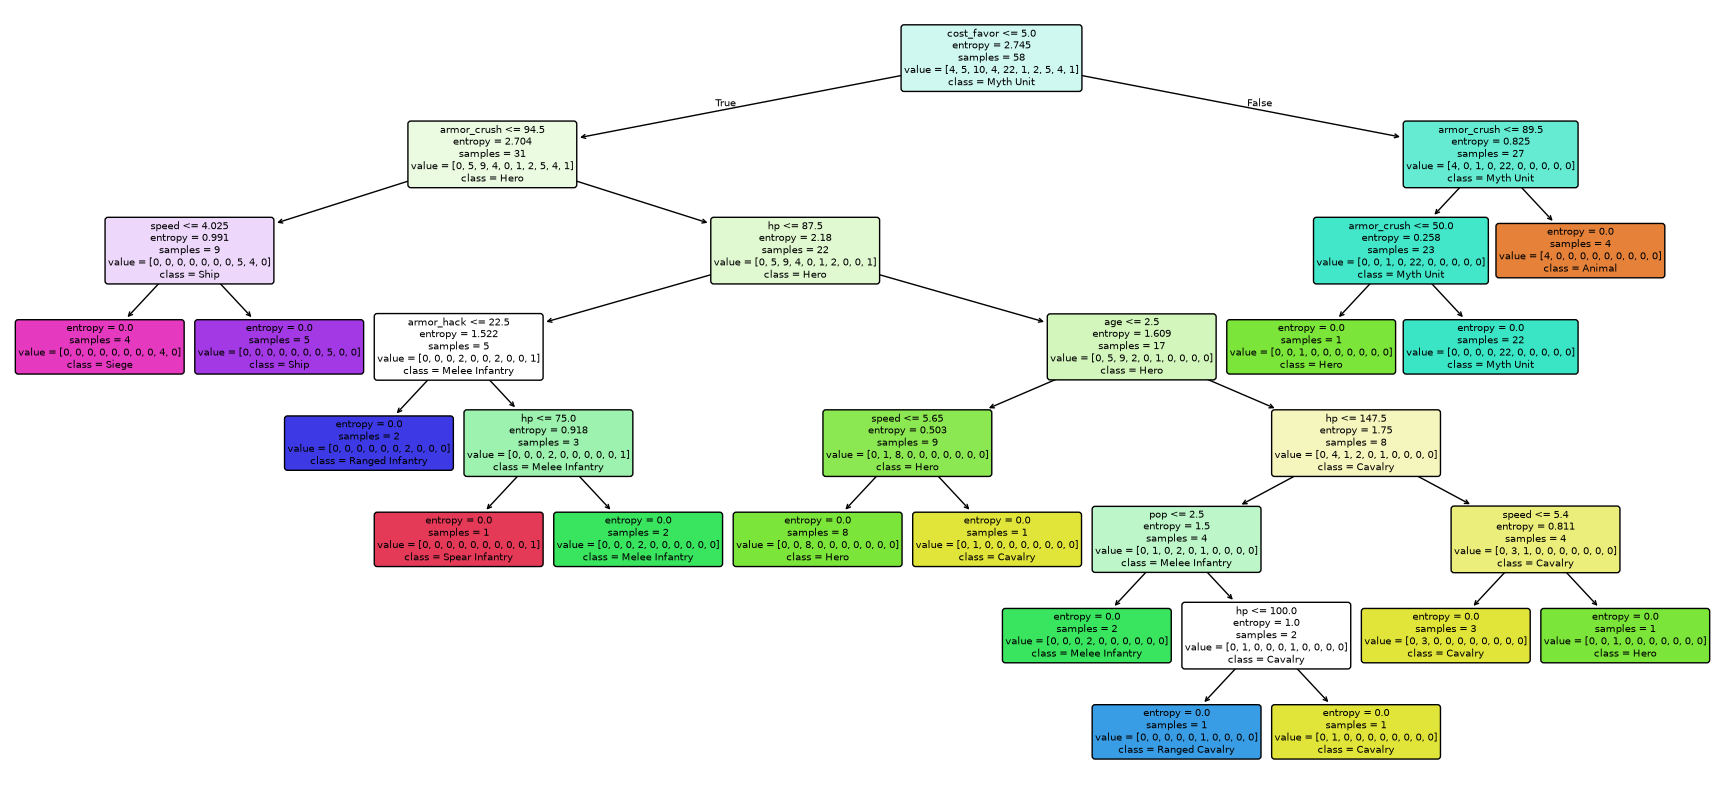

In [143]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arvore, feature_names=ATRIBUTOS, class_names=arvore.classes_,
          filled=True, rounded=True, fontsize=7, ax=ax)
plt.show()



avaliar no conjunto de teste

Acurácia: 0.64


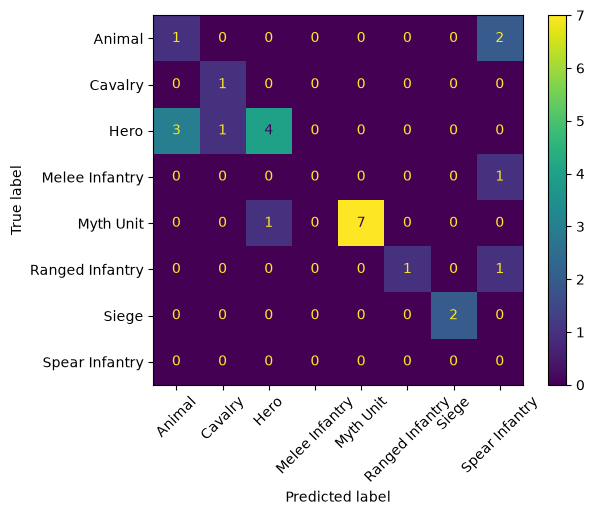

In [144]:
y_pred = arvore.predict(X_test) #testar

print("Acurácia:", round(accuracy_score(y_test, y_pred), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.show()

Validação cruzada

In [145]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=10, shuffle=True, random_state=42)

modelo = DecisionTreeClassifier(criterion="entropy", random_state=42)
scores = cross_val_score(modelo, X, y, cv=kf)

print(scores.round(2))                                    #10 acurácias, uma por rodada
print(f"média={scores.mean():.3f}  desvio={scores.std():.3f}")

[0.78 0.78 0.89 0.75 0.88 0.62 0.88 0.62 0.62 0.88]
média=0.769  desvio=0.105


Poda da arvore

In [146]:
import numpy as np

caminho = DecisionTreeClassifier(criterion="entropy", random_state=42).cost_complexity_pruning_path(X, y)
#Calcula todos os valores de alpha = possíveis para essa árvore

for alpha in np.unique(caminho.ccp_alphas.round(4)):
    #arvore igual, mas podada com esse alpha
    m = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha, random_state=42)

    acc = cross_val_score(m, X, y, cv=kf).mean()  #Acurácia média na validação cruzada

    print(f"alpha={alpha:.4f}  acc_cv={acc:.3f}  folhas={m.fit(X, y).get_n_leaves()}")


alpha=0.0000  acc_cv=0.769  folhas=18
alpha=0.0241  acc_cv=0.769  folhas=17
alpha=0.0332  acc_cv=0.769  folhas=15
alpha=0.0435  acc_cv=0.781  folhas=14
alpha=0.0470  acc_cv=0.781  folhas=13
alpha=0.0499  acc_cv=0.793  folhas=13
alpha=0.0626  acc_cv=0.781  folhas=12
alpha=0.0664  acc_cv=0.746  folhas=10
alpha=0.0831  acc_cv=0.760  folhas=9
alpha=0.1125  acc_cv=0.710  folhas=8
alpha=0.1168  acc_cv=0.710  folhas=7
alpha=0.1417  acc_cv=0.626  folhas=6
alpha=0.1446  acc_cv=0.604  folhas=5
alpha=0.1695  acc_cv=0.540  folhas=5
alpha=0.2952  acc_cv=0.540  folhas=3
alpha=0.4308  acc_cv=0.553  folhas=3
alpha=0.8566  acc_cv=0.399  folhas=1


Decidir o melhor alpha

In [147]:
caminho = DecisionTreeClassifier(criterion="entropy", random_state=42).cost_complexity_pruning_path(X, y)

linhas = []
for alpha in np.unique(caminho.ccp_alphas):          # valores EXATOS, sem round
    m = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha, random_state=42)
    acc = cross_val_score(m, X, y, cv=kf).mean()
    linhas.append((alpha, acc, m.fit(X, y).get_n_leaves()))

tabela = pd.DataFrame(linhas, columns=["alpha", "acc_cv", "folhas"])
print(tabela.round(4))

# melhor acurácia; no empate, menos folhas (árvore mais simples)
ALPHA = tabela.sort_values(["acc_cv", "folhas"], ascending=[False, True]).iloc[0]["alpha"]
print("alpha escolhido:", ALPHA)

     alpha  acc_cv  folhas
0   0.0000  0.7694      18
1   0.0241  0.7694      17
2   0.0332  0.7694      15
3   0.0435  0.7806      14
4   0.0470  0.7806      13
5   0.0499  0.7931      12
6   0.0626  0.7806      11
7   0.0664  0.7458      10
8   0.0831  0.7597       9
9   0.1125  0.7097       8
10  0.1168  0.7097       7
11  0.1417  0.6264       6
12  0.1446  0.6042       5
13  0.1695  0.5403       4
14  0.2952  0.5403       3
15  0.4308  0.5528       2
16  0.8566  0.3986       1
alpha escolhido: 0.04990011385634087


boosting

In [148]:
from sklearn.ensemble import AdaBoostClassifier

candidatos = {
    "Árvore (entropia, sem poda)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Árvore podada": DecisionTreeClassifier(criterion="entropy", ccp_alpha=ALPHA, random_state=42),
    "AdaBoost + Stump (profundidade 1)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=42),
    "AdaBoost + árvores (profundidade 4)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
        n_estimators=50, random_state=42),
}

resultados = {nome: cross_val_score(m, X, y, cv=kf).mean() for nome, m in candidatos.items()}
pd.Series(resultados).sort_values(ascending=False).round(3)

AdaBoost + árvores (profundidade 4)    0.794
Árvore podada                          0.793
Árvore (entropia, sem poda)            0.769
AdaBoost + Stump (profundidade 1)      0.635
dtype: float64

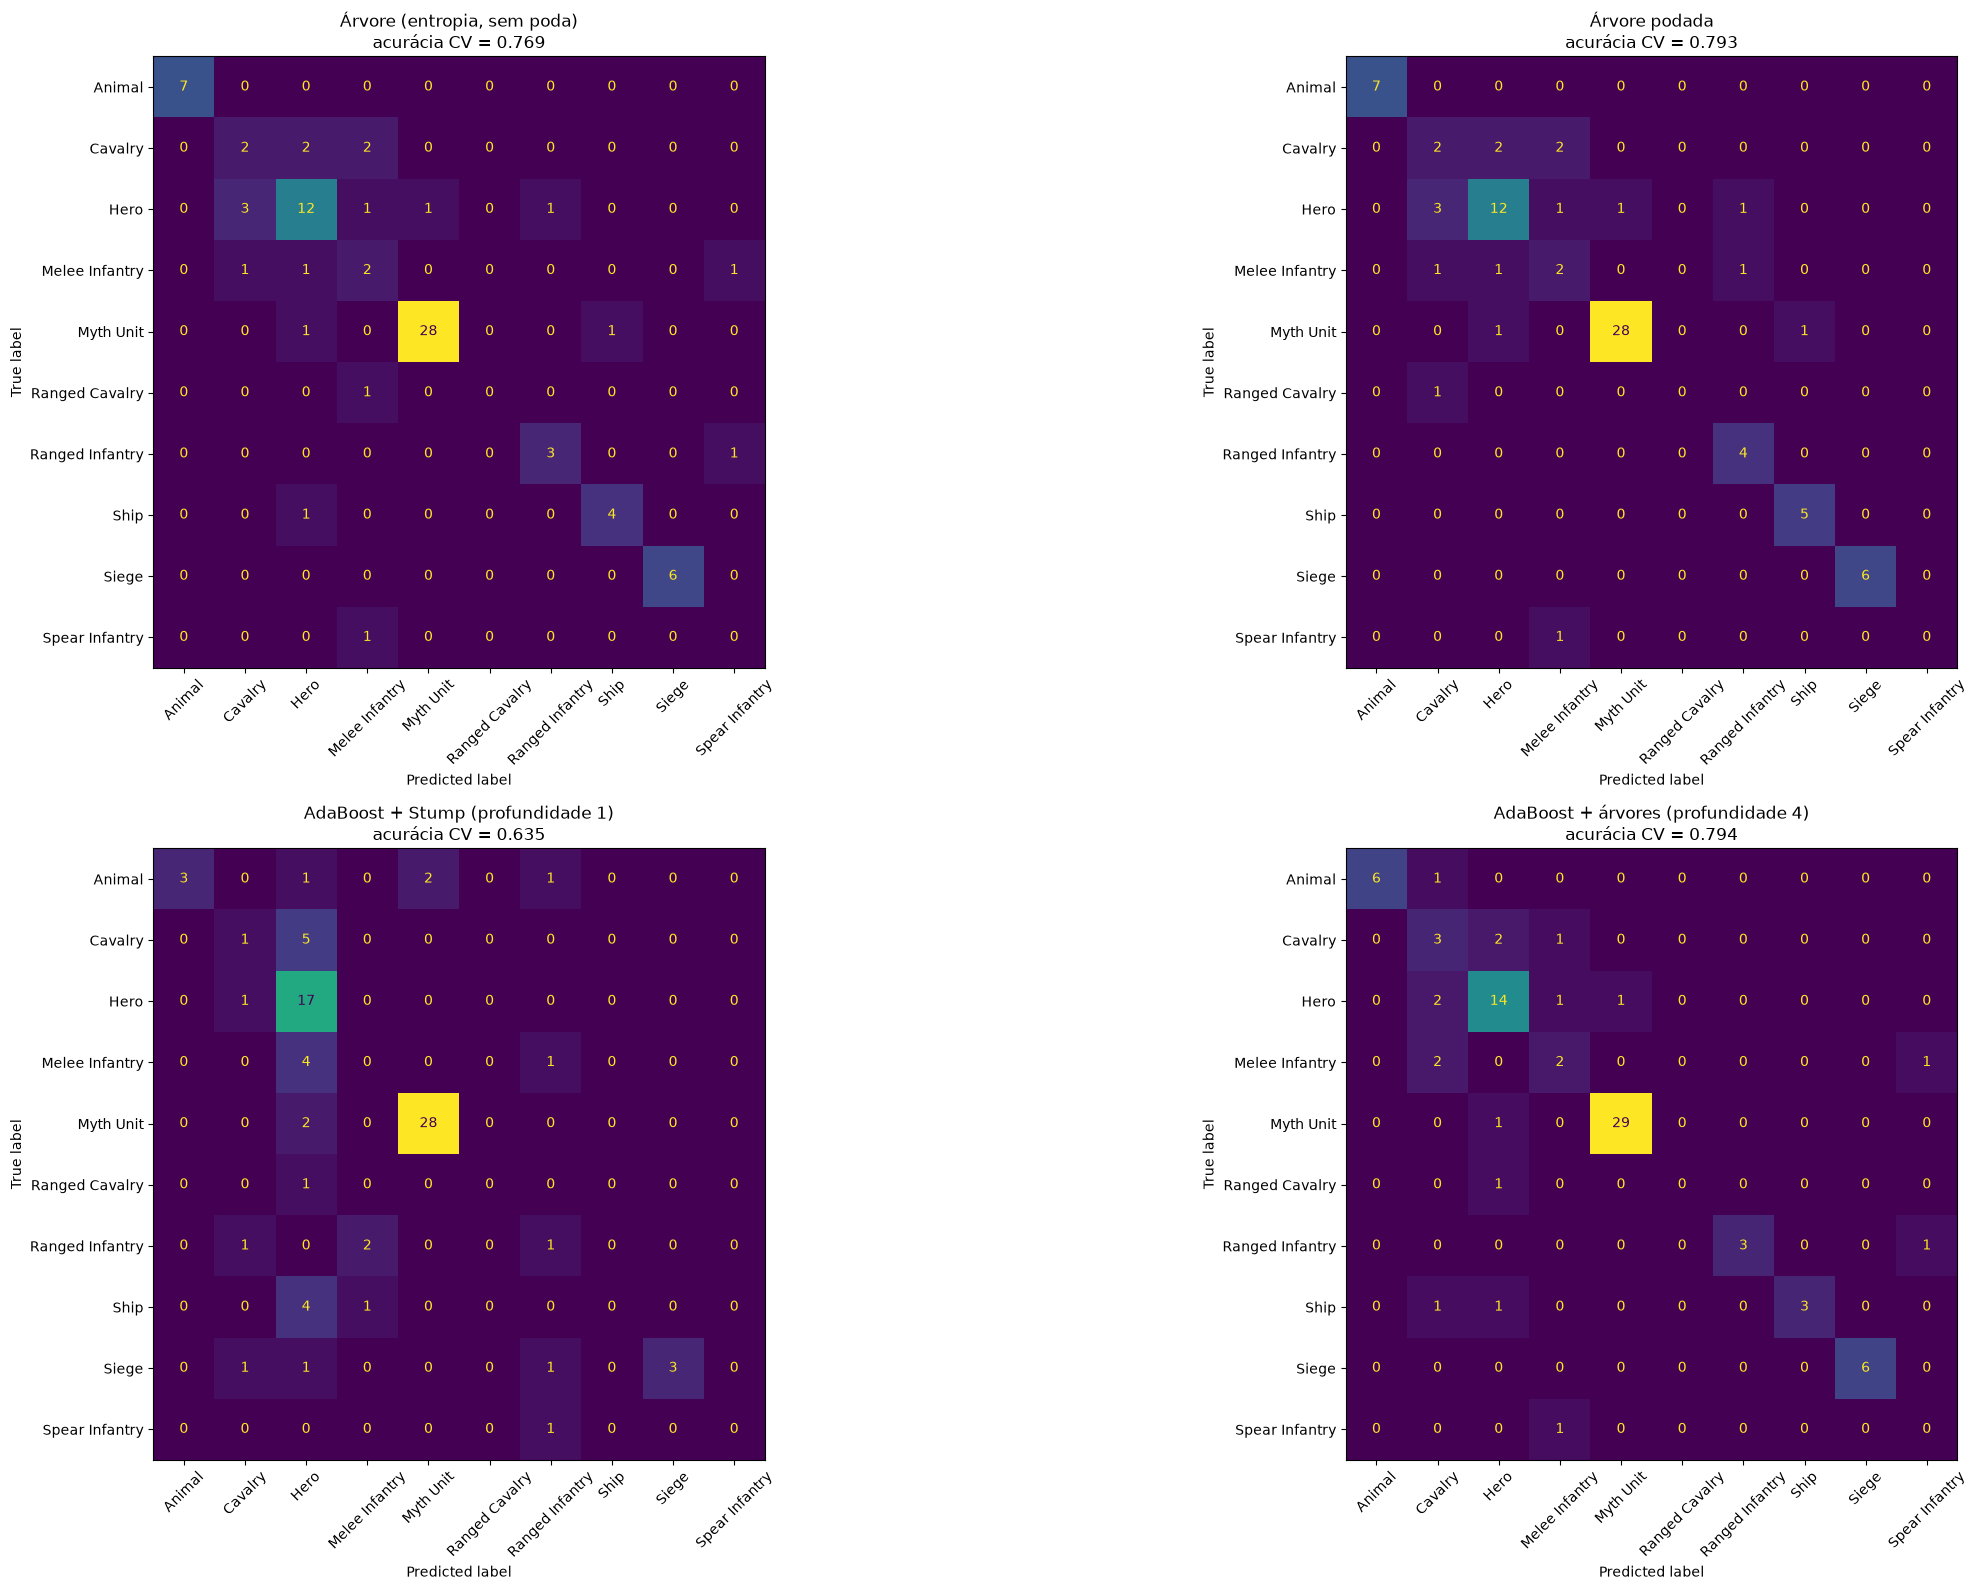

In [152]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import accuracy_score

classes = sorted(y.unique())
preds_cv = {nome: cross_val_predict(m, X, y, cv=kf) for nome, m in candidatos.items()}
fig, axes = plt.subplots(2, 2, figsize=(26, 16))
for ax, (nome, p) in zip(axes.ravel(), resultados.items()):
    p = preds_cv[nome]

    ConfusionMatrixDisplay.from_predictions(
        y,
        p,
        labels=classes,
        xticks_rotation=45,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(f"{nome}\nacurácia CV = {resultados[nome]:.3f}")
plt.tight_layout()
plt.show()

Treinar o melhor modelo 

In [153]:
from sklearn.tree import export_text

arvore_final = DecisionTreeClassifier(criterion="entropy", ccp_alpha=ALPHA, random_state=42).fit(X, y)

print(export_text(arvore_final, feature_names=ATRIBUTOS))
pd.Series(arvore_final.feature_importances_, index=ATRIBUTOS).sort_values(ascending=False).round(3)

|--- armor_crush <= 94.50
|   |--- cost_favor <= 9.00
|   |   |--- speed <= 4.03
|   |   |   |--- class: Siege
|   |   |--- speed >  4.03
|   |   |   |--- class: Ship
|   |--- cost_favor >  9.00
|   |   |--- class: Myth Unit
|--- armor_crush >  94.50
|   |--- hp <= 87.50
|   |   |--- range <= 1.50
|   |   |   |--- cost_favor <= 2.00
|   |   |   |   |--- class: Melee Infantry
|   |   |   |--- cost_favor >  2.00
|   |   |   |   |--- class: Animal
|   |   |--- range >  1.50
|   |   |   |--- class: Ranged Infantry
|   |--- hp >  87.50
|   |   |--- cost_favor <= 7.00
|   |   |   |--- hp <= 215.00
|   |   |   |   |--- age <= 2.50
|   |   |   |   |   |--- armor_pierce <= 32.50
|   |   |   |   |   |   |--- class: Hero
|   |   |   |   |   |--- armor_pierce >  32.50
|   |   |   |   |   |   |--- class: Cavalry
|   |   |   |   |--- age >  2.50
|   |   |   |   |   |--- class: Cavalry
|   |   |   |--- hp >  215.00
|   |   |   |   |--- pop <= 4.50
|   |   |   |   |   |--- class: Hero
|   |   |   |   

armor_crush     0.345
cost_favor      0.276
hp              0.166
speed           0.058
range           0.057
age             0.045
armor_pierce    0.027
pop             0.025
dmg_hack        0.000
dmg_pierce      0.000
dmg_crush       0.000
armor_hack      0.000
train_time      0.000
does_attack     0.000
dtype: float64

In [154]:
nome_final = max(resultados, key=resultados.get)   # melhor da validação cruzada
print("Modelo escolhido:", nome_final)

modelo_final = candidatos[nome_final].fit(X, y)     # agora com 100% dos dados rotulados

previsoes = teste.copy()
previsoes["classe_prevista"] = modelo_final.predict(teste)

previsoes

Modelo escolhido: AdaBoost + árvores (profundidade 4)


,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor,does_attack,classe_prevista
0,3.0,5.0,12.0,0.0,0.0,1.0,800.0,60.0,60.0,80.0,3.60,19.0,15.0,1,Myth Unit
1,2.0,1.0,5.0,0.0,0.0,1.0,50.0,10.0,5.0,99.0,3.00,20.0,5.0,1,Animal
2,2.0,3.0,11.0,5.0,0.0,1.0,400.0,30.0,50.0,99.0,3.80,17.0,5.0,1,Hero
3,3.0,2.0,0.0,6.0,0.0,20.0,60.0,15.0,15.0,99.0,3.75,12.0,0.0,1,Ranged Infantry
4,3.0,3.0,8.0,0.0,0.0,1.0,120.0,10.0,35.0,99.0,4.00,15.0,0.0,1,Cavalry
5,3.0,2.0,8.0,4.0,0.0,1.0,95.0,15.0,10.0,99.0,3.50,14.0,0.0,1,Melee Infantry
6,4.0,3.0,10.0,0.0,30.0,16.0,180.0,30.0,70.0,50.0,2.50,21.0,0.0,1,Siege
7,4.0,3.0,11.0,10.0,0.0,1.0,140.0,15.0,40.0,99.0,3.50,22.0,0.0,1,Cavalry
8,2.0,3.0,10.0,0.0,8.0,1.0,175.0,50.0,25.0,80.0,4.00,26.0,10.0,1,Myth Unit
9,4.0,5.0,20.0,0.0,0.0,1.0,360.0,60.0,69.0,80.0,4.10,30.0,25.0,1,Myth Unit


In [ ]:
for lin in previsoes.itertuples():
    print(f"{lin}: {lin.classe_prevista}")

Pandas(Index=0, age=3.0, pop=5.0, dmg_hack=12.0, dmg_pierce=0.0, dmg_crush=0.0, range=1.0, hp=800.0, armor_hack=60.0, armor_pierce=60.0, armor_crush=80.0, speed=3.6, train_time=19.0, cost_favor=15.0, does_attack=1, classe_prevista='Myth Unit'): Myth Unit
Pandas(Index=1, age=2.0, pop=1.0, dmg_hack=5.0, dmg_pierce=0.0, dmg_crush=0.0, range=1.0, hp=50.0, armor_hack=10.0, armor_pierce=5.0, armor_crush=99.0, speed=3.0, train_time=20.0, cost_favor=5.0, does_attack=1, classe_prevista='Animal'): Animal
Pandas(Index=2, age=2.0, pop=3.0, dmg_hack=11.0, dmg_pierce=5.0, dmg_crush=0.0, range=1.0, hp=400.0, armor_hack=30.0, armor_pierce=50.0, armor_crush=99.0, speed=3.8, train_time=17.0, cost_favor=5.0, does_attack=1, classe_prevista='Hero'): Hero
Pandas(Index=3, age=3.0, pop=2.0, dmg_hack=0.0, dmg_pierce=6.0, dmg_crush=0.0, range=20.0, hp=60.0, armor_hack=15.0, armor_pierce=15.0, armor_crush=99.0, speed=3.75, train_time=12.0, cost_favor=0.0, does_attack=1, classe_prevista='Ranged Infantry'): Ranged

In [155]:
print("Modelo final:", nome_final)
print("X:", X.shape,
      "| soma de X:", round(float(X.to_numpy().sum()), 2),
      "| soma do teste:", round(float(teste[ATRIBUTOS].to_numpy().sum()), 2))

# previsão de cada modelo candidato (todos treinados com os 83 registros), lado a lado
comparacao = pd.DataFrame({
    nome: m.fit(X, y).predict(teste[ATRIBUTOS])
    for nome, m in candidatos.items() if "Stump" not in nome     # o Stump é fraco demais
})
comparacao.index.name = "unidade_teste"
comparacao["todos concordam"] = comparacao.nunique(axis=1) == 1
comparacao

Modelo final: AdaBoost + árvores (profundidade 4)
X: (83, 14) | soma de X: 44652.5 | soma do teste: 4501.75


,"Árvore (entropia, sem poda)",Árvore podada,AdaBoost + árvores (profundidade 4),todos concordam
unidade_teste,,,,
0,Myth Unit,Myth Unit,Myth Unit,True
1,Animal,Animal,Animal,True
2,Hero,Hero,Hero,True
3,Ranged Infantry,Ranged Infantry,Ranged Infantry,True
4,Cavalry,Cavalry,Cavalry,True
5,Ranged Cavalry,Cavalry,Melee Infantry,False
6,Siege,Siege,Siege,True
7,Cavalry,Cavalry,Cavalry,True
8,Myth Unit,Myth Unit,Myth Unit,True
